# EN3160 Assignment 3 - Neural Networks

## 230180F - Minaya Fernando
##### Github Repo link - https://github.com/Minu-Fernando/EN3160.git

### Question 01

In [ ]:
import random
import time
import copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

root = Path.cwd() if Path('en3160_assignment_03.pdf').exists() else Path('Assignment 3')
data_dir = root / 'data'
results_dir = root / 'results'
results_dir.mkdir(exist_ok=True)
# Keep downloaded ImageNet weights inside this assignment folder.
torch.hub.set_dir(str(data_dir / 'torch_hub'))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print('Device:', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)


Device: cuda
NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.5.1+cu121


## Question 1
### 1(a) Add a hidden layer with 100 sigmoid nodes
This keeps Listing 1's data loading, initialization, hyperparameters and manual
updates. The required changes are a 100-node sigmoid middle layer, cross-entropy
loss and 10 epochs. The input-output sizes are 3072 -> 100 -> 10.
I use num_workers=0 for compatibility with Windows notebooks.

In [10]:
import torchvision

# 1. Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                      download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                         shuffle=True, num_workers=0)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                     download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                        shuffle=False, num_workers=0)
classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')



Files already downloaded and verified
Files already downloaded and verified


### 1(b) Cross-entropy and manual backpropagation
The output logits are converted to log probabilities using log-sum-exp for numerical
stability. Cross-entropy is $-\frac{1}{N}\sum_i\log p_{i,y_i}$.
Its logit gradient is $(p-y)/N$. The sigmoid derivative is $h(1-h)$.

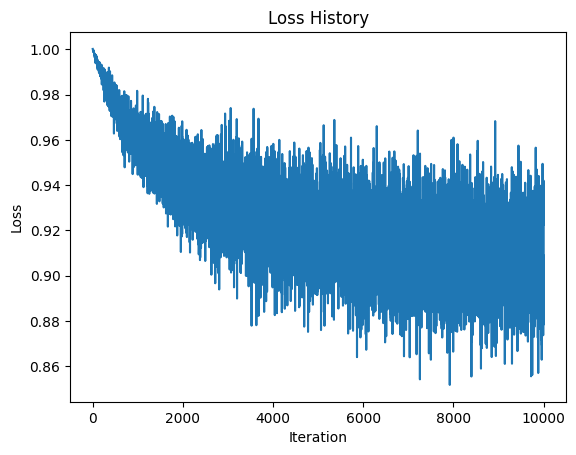

Training accuracy: 30.99%
Test accuracy: 31.02%


In [12]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std
b = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (MSE with regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)

        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    # if t % 1 == 0:
    #     print(
    #         f"Epoch {t + 1}/{iterations}, "
    #         f"Loss: {running_loss / len(trainloader)}"
    #     )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

### 1(c) Training and test accuracy after 10 epochs
These are Listing 1's explicit accuracy loops, with the extra sigmoid layer included
in the forward pass. Evaluation does not update the weights.

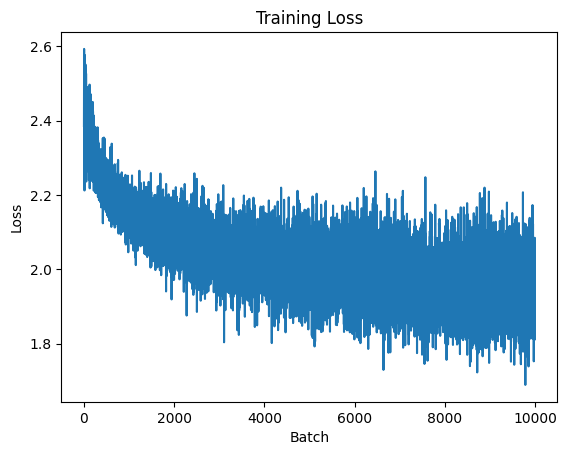

Training accuracy: 33.64%
Test accuracy: 34.00%


In [13]:
# Network settings
input_size = 3 * 32 * 32
hidden_size = 100
num_classes = 10

weights1 = torch.randn(input_size, hidden_size) / input_size**0.5
bias1 = torch.zeros(hidden_size)

weights2 = torch.randn(hidden_size, num_classes) / hidden_size**0.5
bias2 = torch.zeros(num_classes)

epochs = 10
learning_rate = 1e-3
decay = 0.9
reg = 0
losses = []

# Train the network
for epoch in range(epochs):
    for images, labels in trainloader:
        batch_size = images.shape[0]
        images = images.reshape(batch_size, -1)

        hidden = torch.sigmoid(images @ weights1 + bias1)
        scores = hidden @ weights2 + bias2

        loss = nn.functional.cross_entropy(scores, labels)
        loss += reg * ((weights1 ** 2).sum() + (weights2 ** 2).sum())
        losses.append(loss.item())

        # Output layer gradients
        grad_scores = torch.softmax(scores, dim=1)
        grad_scores[torch.arange(batch_size), labels] -= 1
        grad_scores /= batch_size

        grad_weights2 = hidden.T @ grad_scores + 2 * reg * weights2
        grad_bias2 = grad_scores.sum(dim=0)

        # Hidden layer gradients
        grad_hidden = grad_scores @ weights2.T
        grad_hidden *= hidden * (1 - hidden)

        grad_weights1 = images.T @ grad_hidden + 2 * reg * weights1
        grad_bias1 = grad_hidden.sum(dim=0)

        # Update weights and biases
        weights1 -= learning_rate * grad_weights1
        bias1 -= learning_rate * grad_bias1
        weights2 -= learning_rate * grad_weights2
        bias2 -= learning_rate * grad_bias2

    learning_rate *= decay

# Plot training loss
plt.plot(losses)
plt.title("Training Loss")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.show()

# Training accuracy
correct = 0
total = 0

with torch.no_grad():
    for images, labels in trainloader:
        images = images.reshape(images.shape[0], -1)

        hidden = torch.sigmoid(images @ weights1 + bias1)
        scores = hidden @ weights2 + bias2
        predictions = scores.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Training accuracy: {100 * correct / total:.2f}%")

# Test accuracy
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.reshape(images.shape[0], -1)

        hidden = torch.sigmoid(images @ weights1 + bias1)
        scores = hidden @ weights2 + bias2
        predictions = scores.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print(f"Test accuracy: {100 * correct / total:.2f}%")

The learning rate was updated to 1e-3. 

## Question 2 - MNIST: LeNet-5 and a small modern CNN

### Load MNIST and define the common training loop
Both models use the full 60,000 training images and 10,000 test images. I resize
to 32 x 32 for the original LeNet dimensions. The models share the same transforms,
batch size (128), optimizer (Adam), learning rate (0.001), seed and 10-epoch budget.
The test set is used for reporting, not hyperparameter selection.

The training metrics below are measured in evaluation mode after each epoch, so
dropout does not make training and test accuracy incomparable.

In [6]:
mnist_transform = transforms.Compose([
    transforms.Resize((32, 32)), transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])
mnist_train = datasets.MNIST(str(data_dir), train=True, download=True, transform=mnist_transform)
mnist_test = datasets.MNIST(str(data_dir), train=False, download=True, transform=mnist_transform)
# Prepare resized images once, using the same transform for both models.
def cache_mnist(dataset):
    images = torch.stack([dataset[i][0] for i in range(len(dataset))])
    return torch.utils.data.TensorDataset(images, dataset.targets.clone())

mnist_train = cache_mnist(mnist_train)
mnist_test = cache_mnist(mnist_test)
mnist_train_eval = DataLoader(mnist_train, batch_size=256, shuffle=False, num_workers=0)
mnist_test_loader = DataLoader(mnist_test, batch_size=256, shuffle=False, num_workers=0)

def mnist_training_loader():
    generator = torch.Generator().manual_seed(42)
    return DataLoader(mnist_train, batch_size=128, shuffle=True, generator=generator, num_workers=0)

criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader, return_predictions=False):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    targets, predictions = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item()*len(labels)
        pred = logits.argmax(1)
        correct += (pred == labels).sum().item()
        total += len(labels)
        if return_predictions:
            targets.extend(labels.cpu().tolist())
            predictions.extend(pred.cpu().tolist())
    if return_predictions:
        return total_loss/total, 100*correct/total, np.array(targets), np.array(predictions)
    return total_loss/total, 100*correct/total

def train_model(model, train_loader, train_eval_loader, test_loader, optimizer,
                epochs=10, freeze_backbone=False, scheduler=None):
    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}
    for epoch in range(epochs):
        model.train()
        if freeze_backbone:
            # Keep the frozen backbone's batch-normalization statistics fixed too.
            model.eval()
            model.fc.train()
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
        train_loss, train_acc = evaluate(model, train_eval_loader)
        test_loss, test_acc = evaluate(model, test_loader)
        for key, value in zip(history, [train_loss, test_loss, train_acc, test_acc]):
            history[key].append(value)
        print(f'Epoch {epoch+1:2d}/{epochs} | train loss {train_loss:.4f}, acc {train_acc:.2f}% | eval loss {test_loss:.4f}, acc {test_acc:.2f}%', flush=True)
        if scheduler is not None:
            scheduler.step()
    return history

print('MNIST sizes:', len(mnist_train), len(mnist_test))


MNIST sizes: 60000 10000


### 2(a) LeNet-5
The network uses 6 and 16 convolutional channels, tanh activations, average pooling,
and fully connected layers with 120 and 84 neurons. For MNIST classification I use
a 10-logit output and cross-entropy rather than the original RBF output. The second
convolution is fully connected across channels, as in common PyTorch versions.

In [7]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16*5*5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
lenet = LeNet5().to(device)
start = time.time()
lenet_history = train_model(lenet, mnist_training_loader(), mnist_train_eval,
                            mnist_test_loader, optim.Adam(lenet.parameters(), lr=0.001))
lenet_time = time.time()-start
torch.save(lenet.state_dict(), results_dir / 'lenet5.pth')


Epoch  1/10 | train loss 0.1112, acc 96.82% | eval loss 0.1062, acc 96.56%
Epoch  2/10 | train loss 0.0604, acc 98.19% | eval loss 0.0662, acc 97.92%
Epoch  3/10 | train loss 0.0386, acc 98.83% | eval loss 0.0494, acc 98.47%
Epoch  4/10 | train loss 0.0372, acc 98.89% | eval loss 0.0504, acc 98.49%
Epoch  5/10 | train loss 0.0262, acc 99.23% | eval loss 0.0440, acc 98.61%
Epoch  6/10 | train loss 0.0239, acc 99.26% | eval loss 0.0439, acc 98.67%
Epoch  7/10 | train loss 0.0242, acc 99.24% | eval loss 0.0440, acc 98.60%
Epoch  8/10 | train loss 0.0153, acc 99.52% | eval loss 0.0411, acc 98.80%
Epoch  9/10 | train loss 0.0239, acc 99.20% | eval loss 0.0494, acc 98.41%
Epoch 10/10 | train loss 0.0101, acc 99.71% | eval loss 0.0406, acc 98.76%


### 2(b) Modern small CNN
This has three convolutional layers with batch normalization and ReLU. Pooling
reduces the image size, and dropout reduces reliance on individual features.
It uses the same training conditions as LeNet above.

In [8]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.15),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64*4*4, 64), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
small_cnn = SmallCNN().to(device)
start = time.time()
cnn_history = train_model(small_cnn, mnist_training_loader(), mnist_train_eval,
                          mnist_test_loader, optim.Adam(small_cnn.parameters(), lr=0.001))
cnn_time = time.time()-start
torch.save(small_cnn.state_dict(), results_dir / 'small_cnn.pth')


Epoch  1/10 | train loss 0.0513, acc 98.43% | eval loss 0.0475, acc 98.44%
Epoch  2/10 | train loss 0.0474, acc 98.50% | eval loss 0.0435, acc 98.64%
Epoch  3/10 | train loss 0.0273, acc 99.15% | eval loss 0.0300, acc 98.92%
Epoch  4/10 | train loss 0.0292, acc 99.08% | eval loss 0.0301, acc 99.06%
Epoch  5/10 | train loss 0.0202, acc 99.35% | eval loss 0.0268, acc 99.15%
Epoch  6/10 | train loss 0.0159, acc 99.54% | eval loss 0.0215, acc 99.22%
Epoch  7/10 | train loss 0.0131, acc 99.61% | eval loss 0.0223, acc 99.22%
Epoch  8/10 | train loss 0.0132, acc 99.60% | eval loss 0.0246, acc 99.21%
Epoch  9/10 | train loss 0.0174, acc 99.39% | eval loss 0.0281, acc 99.08%
Epoch 10/10 | train loss 0.0085, acc 99.73% | eval loss 0.0211, acc 99.29%


### 2(c) Accuracy/loss plots and confusion matrices
Each confusion matrix uses true labels as rows and predicted labels as columns.
Diagonal entries are correct predictions. Off-diagonal entries show which digits
the network mixes up. The summary reports epoch 10, rather than choosing the best
test epoch.

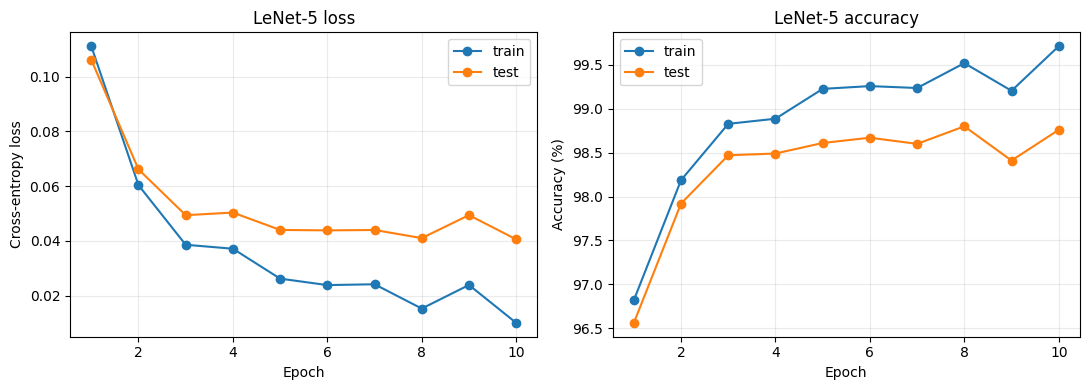

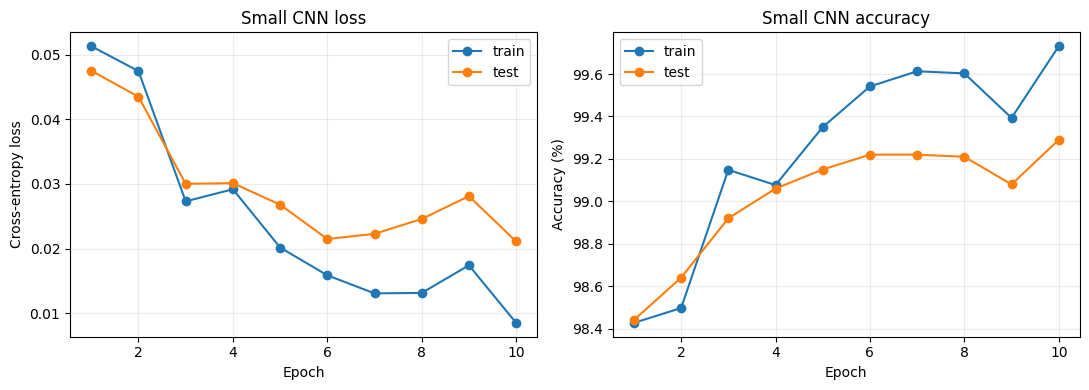

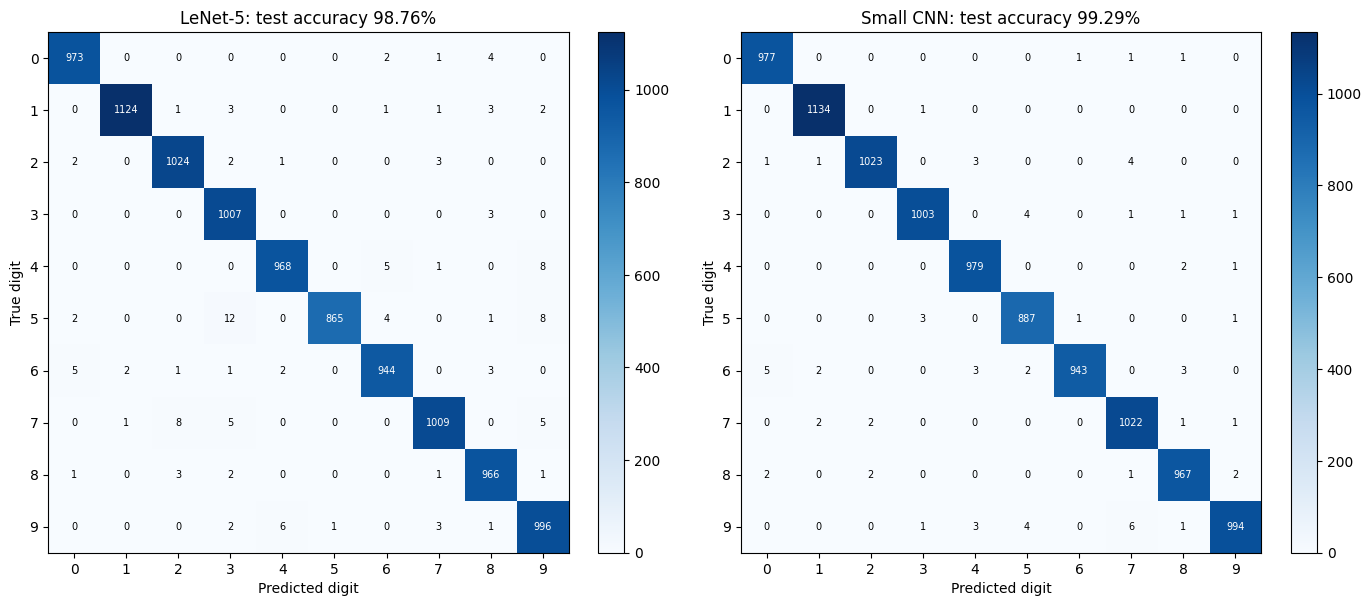

Model       Train acc   Test acc   Train loss  Test loss   Time(s)
LeNet-5        99.71%     98.76%      0.0101     0.0406      86.7
Small CNN      99.73%     99.29%      0.0085     0.0211      93.7


In [9]:
plot_history(lenet_history, 'LeNet-5')
plot_history(cnn_history, 'Small CNN')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for model, name, ax in [(lenet, 'LeNet-5', axes[0]), (small_cnn, 'Small CNN', axes[1])]:
    loss, accuracy, true, pred = evaluate(model, mnist_test_loader, return_predictions=True)
    matrix = np.zeros((10, 10), dtype=int)
    np.add.at(matrix, (true, pred), 1)
    image = ax.imshow(matrix, cmap='Blues')
    for row in range(10):
        for col in range(10):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center', fontsize=7,
                    color='white' if matrix[row, col] > matrix.max()/2 else 'black')
    ax.set(xticks=range(10), yticks=range(10), xlabel='Predicted digit', ylabel='True digit',
           title=f'{name}: test accuracy {accuracy:.2f}%')
    fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

print('Model       Train acc   Test acc   Train loss  Test loss   Time(s)')
for name, h, seconds in [('LeNet-5', lenet_history, lenet_time), ('Small CNN', cnn_history, cnn_time)]:
    print(f"{name:10s} {h['train_acc'][-1]:9.2f}% {h['test_acc'][-1]:9.2f}% {h['train_loss'][-1]:11.4f} {h['test_loss'][-1]:10.4f} {seconds:9.1f}")


The modern model has batch normalization and dropout, but it is not guaranteed
to win every run. The final test accuracies and confusion matrices give the actual
comparison. Both models see exactly the same data split and shuffled batch order.
Differences in parameter count and training time should also be considered.

## Question 3 - ResNet18 transfer learning for ants and bees

I follow the [PyTorch transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).
Both methods start from ImageNet1K-pretrained ResNet18 and replace its final layer
with two outputs. I use the supplied training/validation split and train for 10
epochs. The validation set is the evaluation set here; there is no separate test
split in this dataset. Results are reported at the final epoch.

Training images use random crops and horizontal flips. Evaluation uses a fixed
resize and centre crop. Both use ImageNet normalization. Training accuracy is
measured on the training images with deterministic evaluation transforms.

In [10]:
imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(imagenet_mean, imagenet_std)
])
eval_transform = transforms.Compose([
    transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])
ants_dir = data_dir / 'hymenoptera_data'
ants_train = datasets.ImageFolder(ants_dir / 'train', train_transform)
ants_train_eval = datasets.ImageFolder(ants_dir / 'train', eval_transform)
ants_val = datasets.ImageFolder(ants_dir / 'val', eval_transform)
ants_train_eval_loader = DataLoader(ants_train_eval, batch_size=16, shuffle=False, num_workers=0)
ants_val_loader = DataLoader(ants_val, batch_size=16, shuffle=False, num_workers=0)

def ants_training_loader():
    return DataLoader(ants_train, batch_size=16, shuffle=True, num_workers=0,
                      generator=torch.Generator().manual_seed(42))

weights = models.ResNet18_Weights.IMAGENET1K_V1
print('Classes:', ants_train.classes)
print('Training:', len(ants_train), 'Validation:', len(ants_val))


Classes: ['ants', 'bees']
Training: 244 Validation: 153


### 3(a) Fine-tune the network
All layers are trainable. I use SGD with learning rate 0.001, momentum 0.9, and
reduce the learning rate by a factor of 0.1 after seven epochs. Fine-tuning can
adapt the pretrained features to the new task, but may overfit a small dataset.

In [11]:
set_seed()
finetuned = models.resnet18(weights=weights)
finetuned.fc = nn.Linear(finetuned.fc.in_features, 2)
finetuned = finetuned.to(device)
optimizer = optim.SGD(finetuned.parameters(), lr=0.001, momentum=0.9)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
start = time.time()
fine_history = train_model(finetuned, ants_training_loader(), ants_train_eval_loader,
                           ants_val_loader, optimizer, epochs=10, scheduler=scheduler)
fine_time = time.time()-start
torch.save(finetuned.state_dict(), results_dir / 'resnet18_finetuned.pth')


Epoch  1/10 | train loss 0.2829, acc 90.57% | eval loss 0.3135, acc 90.20%
Epoch  2/10 | train loss 0.1306, acc 95.49% | eval loss 0.1916, acc 93.46%
Epoch  3/10 | train loss 0.0940, acc 97.95% | eval loss 0.1767, acc 94.12%
Epoch  4/10 | train loss 0.0732, acc 98.36% | eval loss 0.1801, acc 94.77%
Epoch  5/10 | train loss 0.0560, acc 98.77% | eval loss 0.1590, acc 94.77%
Epoch  6/10 | train loss 0.0398, acc 99.59% | eval loss 0.1547, acc 95.42%
Epoch  7/10 | train loss 0.0301, acc 100.00% | eval loss 0.1902, acc 93.46%
Epoch  8/10 | train loss 0.0270, acc 100.00% | eval loss 0.1831, acc 94.77%
Epoch  9/10 | train loss 0.0254, acc 99.59% | eval loss 0.1678, acc 94.77%
Epoch 10/10 | train loss 0.0245, acc 100.00% | eval loss 0.1665, acc 94.77%


### 3(b) Use ResNet18 as a feature extractor
The pretrained backbone is frozen and only the new final layer is trained. I also
keep the backbone in evaluation mode during training so batch-normalization running
statistics stay fixed. The optimizer and epoch budget are the same as in 3(a).
The seed is reset so both methods start with the same new classifier weights.

In [12]:
set_seed()
feature_model = models.resnet18(weights=weights)
for parameter in feature_model.parameters():
    parameter.requires_grad = False
feature_model.fc = nn.Linear(feature_model.fc.in_features, 2)
feature_model = feature_model.to(device)
optimizer = optim.SGD(feature_model.fc.parameters(), lr=0.001, momentum=0.9)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
start = time.time()
feature_history = train_model(feature_model, ants_training_loader(), ants_train_eval_loader,
                              ants_val_loader, optimizer, epochs=10,
                              freeze_backbone=True, scheduler=scheduler)
feature_time = time.time()-start
torch.save(feature_model.state_dict(), results_dir / 'resnet18_features.pth')


Epoch  1/10 | train loss 0.2399, acc 95.08% | eval loss 0.2459, acc 95.42%
Epoch  2/10 | train loss 0.1464, acc 95.90% | eval loss 0.1585, acc 95.42%
Epoch  3/10 | train loss 0.1020, acc 97.95% | eval loss 0.1433, acc 94.77%
Epoch  4/10 | train loss 0.0930, acc 97.13% | eval loss 0.1283, acc 95.42%
Epoch  5/10 | train loss 0.0835, acc 97.54% | eval loss 0.1250, acc 96.08%
Epoch  6/10 | train loss 0.0780, acc 97.54% | eval loss 0.1258, acc 95.42%
Epoch  7/10 | train loss 0.0724, acc 97.95% | eval loss 0.1297, acc 95.42%
Epoch  8/10 | train loss 0.0719, acc 97.95% | eval loss 0.1296, acc 95.42%
Epoch  9/10 | train loss 0.0722, acc 97.54% | eval loss 0.1258, acc 95.42%
Epoch 10/10 | train loss 0.0712, acc 97.54% | eval loss 0.1267, acc 95.42%


### Question 3 - Results and comparison
The shared plotting function calls the evaluation split `test` internally. For this
question the plotted test curves refer to the supplied **validation** split.
Feature extraction trains fewer parameters and should usually take less training
time. Fine-tuning can learn more task-specific features. The table gives the actual
accuracy and time trade-off for this run.

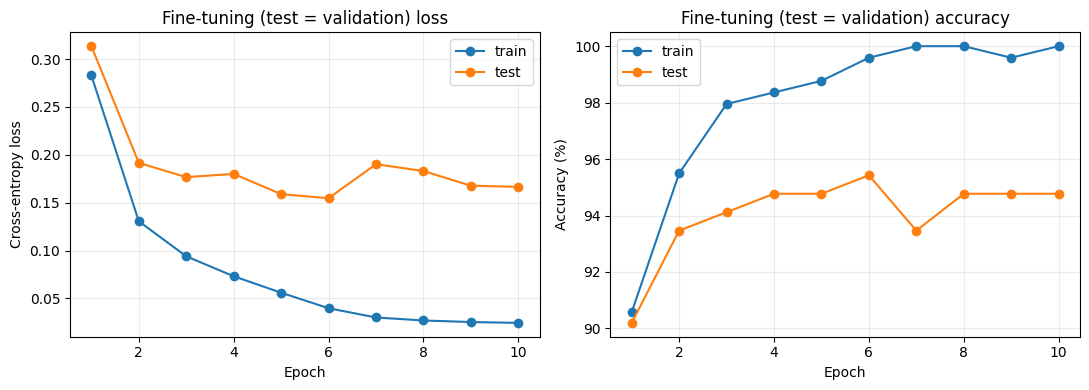

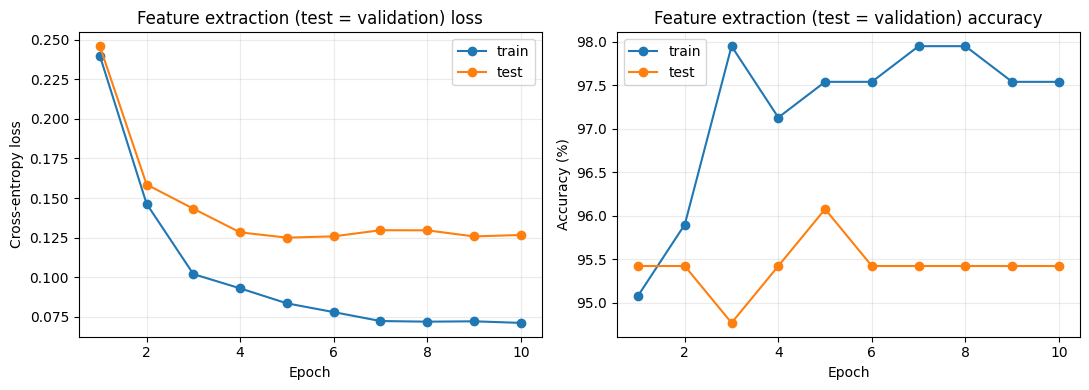

Method              Train acc   Val acc   Val loss   Trainable params   Time(s)
Fine-tuning           100.00%    94.77%     0.1665          11177538      89.0
Feature extraction     97.54%    95.42%     0.1267              1026      94.8


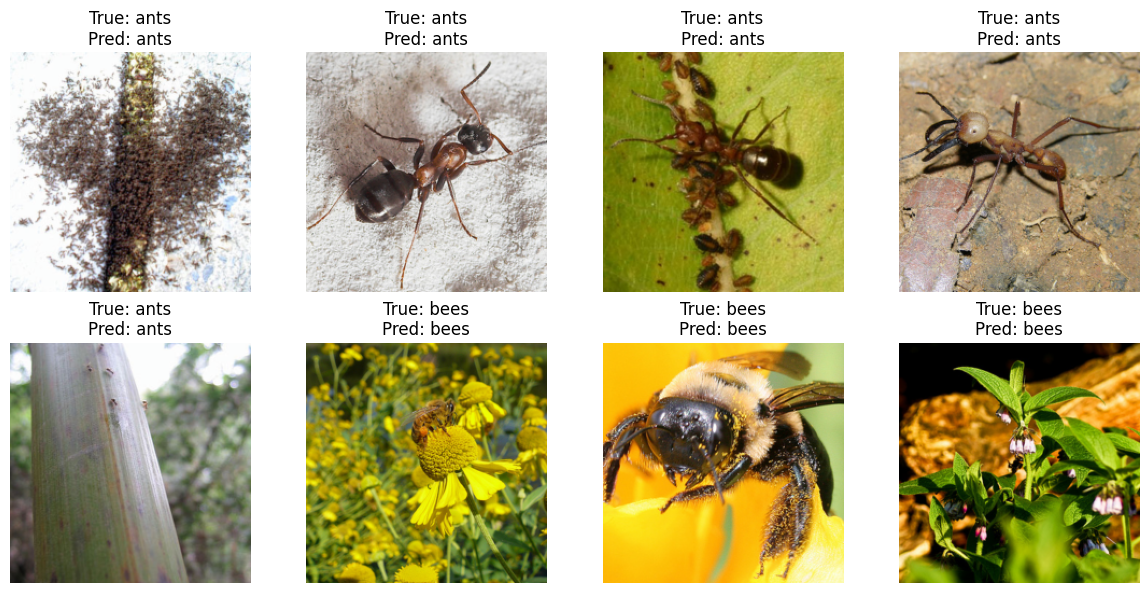

In [13]:
plot_history(fine_history, 'Fine-tuning (test = validation)')
plot_history(feature_history, 'Feature extraction (test = validation)')
print('Method              Train acc   Val acc   Val loss   Trainable params   Time(s)')
for name, model, h, seconds in [('Fine-tuning', finetuned, fine_history, fine_time),
                               ('Feature extraction', feature_model, feature_history, feature_time)]:
    count = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"{name:19s} {h['train_acc'][-1]:8.2f}% {h['test_acc'][-1]:8.2f}% {h['test_loss'][-1]:10.4f} {count:17d} {seconds:9.1f}")

# Display a few predictions from the validation set.
finetuned.eval()
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    image, label = ants_val[i*15]
    with torch.no_grad():
        pred = finetuned(image.unsqueeze(0).to(device)).argmax(1).item()
    display_image = image.permute(1, 2, 0).numpy()*np.array(imagenet_std)+np.array(imagenet_mean)
    ax.imshow(np.clip(display_image, 0, 1))
    ax.set_title(f'True: {ants_val.classes[label]}\nPred: {ants_val.classes[pred]}')
    ax.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
import json
all_histories = {'manual_dense': dense_history, 'lenet5': lenet_history,
                 'small_cnn': cnn_history, 'fine_tuning': fine_history,
                 'feature_extraction': feature_history}
with open(results_dir / 'training_history.json', 'w') as file:
    json.dump(all_histories, file, indent=2)
torch.save({'w1': w1.cpu(), 'b1': b1.cpu(), 'w2': w2.cpu(), 'b2': b2.cpu()},
           results_dir / 'manual_dense.pth')
print('Results saved in:', results_dir)
